In [4]:
# YOLO 및 RoboFlow 사용하기 위한 설치 명령문
!pip install -q ultralytics roboflow

In [5]:
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO
from roboflow import Roboflow
from pathlib import Path
  # RoboFlow로부터 다운로드받은 데이터셋 접근

# RoboFlow :: 코딩X 이미지/영상 처리와 관련한 AI 모델 구축하는 브라우저 서비스

In [9]:
# 우리는 RoboFlow를 다른 사용자 AI 모델의 "데이터셋 다운로드" 하는 데에 사용

# RoboFlow 준비
# 1. 회원가입(계정 생성) + 워크스페이스 생성
#      => 계정 Private API키, 워크스페이스 ID값 받아올 수 있음
# 2. Universe 항목에서 검색을 하여 원하는 모델 찾기
# 3. 원하는 모델 가져오면서 프로젝트 생성
#      => 프로젝트 ID 받아올 수 있음
# 4. Upload Data에서, 임의의 학습 이미지 올리기
# 5. Versions에서, 해당 모델에 대한 버전 생성

# RoboFlow 프로젝트 접근 준비
rf = Roboflow(api_key="zwwbjAJr0HahUZt4HTMI")
project = rf.workspace("demo").project("hymenoptera-tuzcc-pqu8q")

# 데이터셋 다운로드
dataset = project.version(1).download('yolov11')

loading Roboflow workspace...
loading Roboflow project...


In [10]:
# YOLO 모델 불러오기
model = YOLO('yolo11n.pt')

# 기 학습된 YOLO에 대해, 추가 학습 진행
model.train(
    data=dataset.location + "/data.yaml",    # dataset을 학습용 데이터로 설정
    epochs=10,        # 학습 반복 횟수 (위 데이터셋 값을 10번 반복 학습)
    imgsz=256        # 이미지 크기
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Hymenoptera-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opt

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7e4ba3c9ce60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [12]:
# 추가 학습을 시킨 모델 불러오기

# 성능이 가장 좋았던 모델 가져오기
Model_Path = model.trainer.best
trained_model = YOLO(str(Model_Path))

# trained_model을 통해, 객체 검출 진행해줄 예정

In [19]:
# 테스트 진행

# 데이터셋에 있는 테스트용 이미지 불러오기 (.jpg 형식만 갖고옴)
test_img = list(
    Path(dataset.location + '/test/images').glob('*.jpg')
)

# 여러 테스트 이미지 중 하나 선택
Image_Path = test_img[2]

# 물체(객체) 검출 진행 (results는 배열)
results = trained_model(
    str(Image_Path),
    conf = 0.2
)
# 2번 테스트 이미지(문제)에서, 20% 이상의 신뢰도(조건)를 가진 객체 검출하겠다.
# 객체 검출 결과를 results에 저장

# 첫번째 사진에 대한 검출 결과를 result에 저장
result = results[0]


image 1/1 /content/Hymenoptera-1/test/images/images-2022-02-10T105429-035_jpeg.rf.a52bf2c5e8ab58d6c8a32231b38470a9.jpg: 192x256 1 Abeille, 9.7ms
Speed: 0.8ms preprocess, 9.7ms inference, 1.5ms postprocess per image at shape (1, 3, 192, 256)


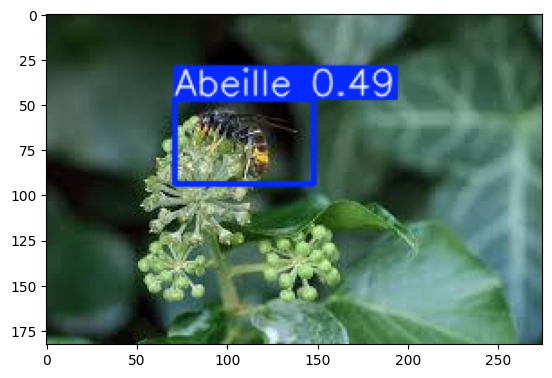

In [20]:
# 물체(객체) 검출 결과를 그림을 그려서 이미지로 생성 -> result_img
result_img = result.plot()

result_rgb = cv2.cvtColor(
    result_img,
    cv2.COLOR_BGR2RGB
)

plt.imshow(result_rgb)
plt.show()